# Linear discriminant

Linear Discriminant Analysis (LDA) is a supervised machine learning algorithm used for dimensionality reduction and classification

# For more info click the link below

https://docs.google.com/document/d/10yHRP7pMnJPhDpYsc0-NdGvrHi7_-eGb2pBj2Yd0-3w/edit?usp=sharing

# Notes and Q and answer


https://docs.google.com/document/d/1cufp3MNK5F4TCs9xikhoMMD2e_3prXRTHr9WglTA9dY/edit?usp=sharing

# Coding

# import libraries 

In [2]:
import numpy as np                                      # Numerical calculations
import pandas as pd                                     # Data manipulation
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import load_wine                  # Built-in Wine dataset
from sklearn.model_selection import train_test_split    # Split data into training and testing sets
from sklearn.preprocessing import StandardScaler        # Standardize feature values
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis  # LDA algorithm

# load the dataset

In [4]:
wine = load_wine()

X = wine.data
y = wine.target 

print("X shape:", X.shape)
print("X shape:", y.shape)


print("Classes:", np.unique(y))                        # Show the available classes

X shape: (178, 13)
X shape: (178,)
Classes: [0 1 2]


Original features: 13
LDA features: 2
Explained variance ratio: [0.69352994 0.30647006]
LDA Accuracy: 0.9444444444444444


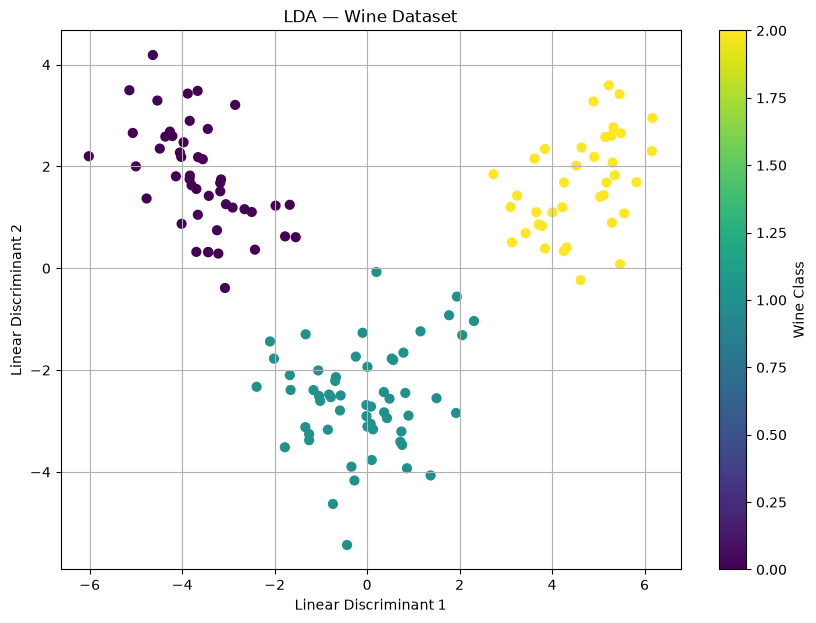

In [5]:
import numpy as np                                      # Numerical calculations
import pandas as pd                                     # Data manipulation
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import load_wine                  # Built-in Wine dataset
from sklearn.model_selection import train_test_split    # Split data into train and test sets
from sklearn.preprocessing import StandardScaler        # Standardize features
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis  # LDA algorithm
from sklearn.metrics import accuracy_score              # Classification accuracy


wine = load_wine()                                      # Load the Wine dataset

X = wine.data                                           # 13 original features
y = wine.target                                         # Three class labels


X_train, X_test, y_train, y_test = train_test_split(
    X,                                                    # Input features
    y,                                                    # Target classes
    test_size=0.2,                                       # Keep 20% for testing
    random_state=42,                                     # Reproducible split
    stratify=y                                            # Preserve class proportions
)


scaler = StandardScaler()                               # Create the scaler

X_train_scaled = scaler.fit_transform(
    X_train                                               # Learn scaling parameters from training data
)

X_test_scaled = scaler.transform(
    X_test                                                # Apply training scaling to test data
)


lda = LinearDiscriminantAnalysis(
    n_components=2                                      # Maximum possible for 3 classes: 3 - 1 = 2
)


X_train_lda = lda.fit_transform(
    X_train_scaled,                                      # Training features
    y_train                                               # Class labels used to find discriminant directions
)


X_test_lda = lda.transform(
    X_test_scaled                                        # Transform unseen test data using learned directions
)


print("Original features:", X.shape[1])                 # 13
print("LDA features:", X_train_lda.shape[1])            # 2

print(
    "Explained variance ratio:",
    lda.explained_variance_ratio_                        # Discriminative information captured by each LD
)


y_pred = lda.predict(
    X_test_scaled                                        # Predict test-set classes
)


accuracy = accuracy_score(
    y_test,                                               # Actual classes
    y_pred                                                # Predicted classes
)

print("LDA Accuracy:", accuracy)


plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_train_lda[:, 0],                                   # Linear Discriminant 1
    X_train_lda[:, 1],                                   # Linear Discriminant 2
    c=y_train,                                           # Color according to class
    cmap="viridis",
    s=40
)

plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("LDA — Wine Dataset")

plt.colorbar(
    scatter,
    label="Wine Class"
)

plt.grid()
plt.show()